In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import mnist
from tensorflow.keras.optimizers import SGD

In [3]:
(x_train,y_train) ,(x_test,y_test) = mnist.load_data()
print("Training Images",x_train.shape)
print("Training Labels",y_train.shape)

print("Testing Images",x_test.shape)
print("testing Labels",y_test.shape)

Training Images (60000, 28, 28)
Training Labels (60000,)
Testing Images (10000, 28, 28)
testing Labels (10000,)


In [4]:
x_train = x_train.astype("float32")/255.0
x_test = x_test.astype("float32")/255.0

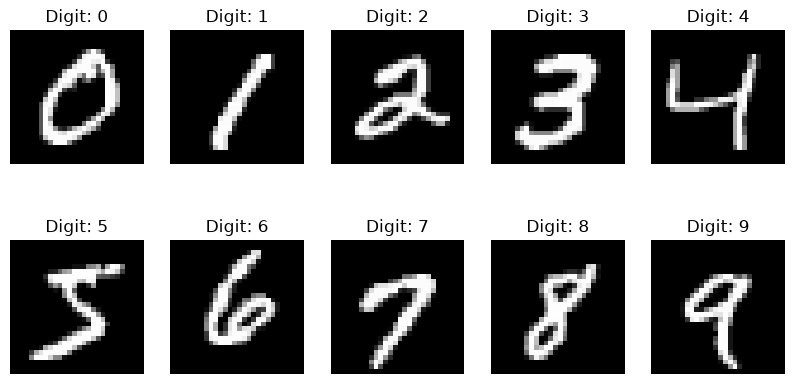

In [5]:
# Display digits 0 to 9 before training

plt.figure(figsize=(10, 5))

for i in range(10):
    n = np.where(y_train == i)[0][0]

    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[n], cmap='gray')
    plt.title("Digit: " + str(i))
    plt.axis('off')



In [11]:
model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(256,activation="relu"),
    Dense(128,activation="relu"),
    Dense(10,activation="softmax")
])

model.summary()

C:\Users\PRASANNA\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
    optimizer = 'sgd',
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [13]:
h = model.fit(
    x_train,
    y_train,
    validation_split=0.1,
    epochs=10,
    batch_size=128
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7110 - loss: 1.2539 - val_accuracy: 0.8847 - val_loss: 0.5551
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8744 - loss: 0.4985 - val_accuracy: 0.9133 - val_loss: 0.3528
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8953 - loss: 0.3857 - val_accuracy: 0.9237 - val_loss: 0.2959
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9052 - loss: 0.3393 - val_accuracy: 0.9268 - val_loss: 0.2682
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9127 - loss: 0.3112 - val_accuracy: 0.9298 - val_loss: 0.2470
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9173 - loss: 0.2907 - val_accuracy: 0.9340 - val_loss: 0.2341
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9219 - loss: 0.2742 - val_accuracy: 0.9382 - val_loss: 0.2213
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9265 - loss: 0.2601 - val_accuracy: 0.

In [31]:
test_loss, test_acc = model.evaluate(x_test, y_test)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9364 - loss: 0.2220
Test Loss: 0.22204050421714783
Test Accuracy: 93.63999962806702 %


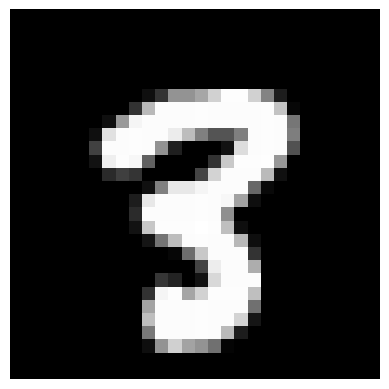

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
Actual: 3
Predicted: 8


In [32]:
n = random.randint(0, len(x_test)-1)

plt.imshow(x_test[n], cmap='gray')
plt.axis('off')
plt.show()

pred = model.predict(
    x_test[n].reshape(1, 28, 28) 
)

print("Actual:", y_test[n])
print("Predicted:", np.argmax(pred))

In [16]:
prediction = model.predict(x_test)
for i in range(10):
    n = np.where(y_test == i)[0][0]

    print("Digit:", i,
          "Prediction:", np.argmax(prediction[n]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Digit: 0 Prediction: 0
Digit: 1 Prediction: 1
Digit: 2 Prediction: 2
Digit: 3 Prediction: 3
Digit: 4 Prediction: 4
Digit: 5 Prediction: 6
Digit: 6 Prediction: 6
Digit: 7 Prediction: 7
Digit: 8 Prediction: 8
Digit: 9 Prediction: 9


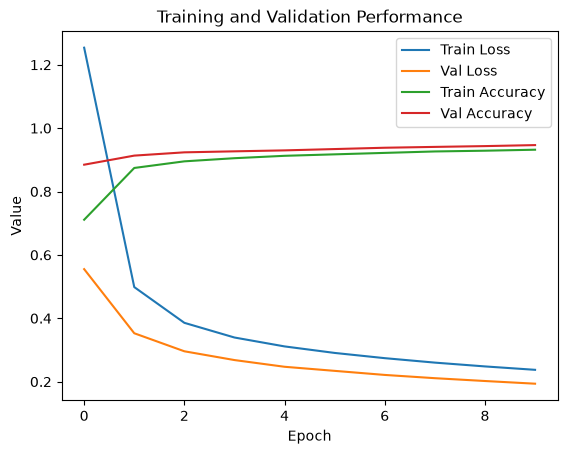

In [17]:
plt.plot(h.history["loss"], label="Train Loss")
plt.plot(h.history["val_loss"], label="Val Loss")
plt.plot(h.history["accuracy"], label="Train Accuracy")
plt.plot(h.history["val_accuracy"], label="Val Accuracy")

plt.legend()
plt.xlabel("Epoch")
plt.ylabel("Value")
plt.title("Training and Validation Performance")
plt.show()
